# Figure 4 regional heterogeneity: real ico5 within-region curves

This notebook implements the real-data first stage of the regional analysis for the frozen Figure 4 design: official ico5 fixed anchors, within-DK-region candidates, nested $K=15$, and pair seed 0. Homologous hemispheres are combined within subject before group inference.

The statistical hierarchy is:

$$\text{pair} \rightarrow \text{anchor × distance-bin median} \rightarrow
\text{subject × bilateral region × distance-bin median} \rightarrow
\text{group median/IQR}.$$

Region-level null curves, $\Delta L(d)$, and residual AUC are deliberately deferred. Therefore this notebook must not interpret regional real curves as null-adjusted physiological effects.

In [16]:
from pathlib import Path
import os
import re
import subprocess
import sys

REPO_ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib as mpl
import matplotlib.pyplot as plt
import nibabel.freesurfer.io as fsio
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from nilearn import plotting, surface

from qc.publication_style import (
    FIGURE_WIDTH_IN, PALETTE, save_publication_figure,
    set_publication_style, style_axes,
)

set_publication_style()

PROJECT_ROOT = REPO_ROOT.parents[1]
FORMAL_ROOT = PROJECT_ROOT / 'results/qc/full_cohort_spatial_scale/figure4_ico5_formal_k15'
MANIFEST = REPO_ROOT / 'manifests/figure4_valid_325_subjects.csv'
PAIR_FILE = FORMAL_ROOT / 'pairs/figure4_geodesic_pairs_all.parquet'
REGION_ROOT = FORMAL_ROOT / 'region_real'
SUBJECT_ROOT = REGION_ROOT / 'subjects'
SUMMARY_DIR = REGION_ROOT / 'cohort'
FIGURE_DIR = REGION_ROOT / 'figures'
TEMPLATE_ROOT = PROJECT_ROOT / 'data/processed/t1_freesurfer/fsaverage'

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# These remain False unless the user explicitly decides to submit jobs.
RUN_SUBJECT_COMPUTE = False
RUN_SUMMARY = False

print(f'Pair table: {PAIR_FILE}')
print(f'Regional output: {REGION_ROOT}')

Pair table: /mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale/figure4_ico5_formal_k15/pairs/figure4_geodesic_pairs_all.parquet
Regional output: /mnt/newStor/paros/paros_WORK/xintong/results/qc/full_cohort_spatial_scale/figure4_ico5_formal_k15/region_real


## Optional computation submission

The full-cohort calculation is kept outside the notebook kernel. The cell below only submits jobs when its corresponding flag is manually changed to `True`. It does not rebuild geodesic neighbourhoods and it does not generate a regional null.

In [17]:
manifest = pd.read_csv(MANIFEST, dtype={'subject_id': str})
n_subjects = len(manifest)
job_environment = os.environ.copy()
job_environment.update({
    'MANIFEST': str(MANIFEST),
    'PAIR_FILE': str(PAIR_FILE),
    'OUTPUT_ROOT': str(REGION_ROOT),
})

if RUN_SUBJECT_COMPUTE:
    command = [
        'sbatch', '--parsable', f'--array=0-{n_subjects - 1}%25',
        str(REPO_ROOT / 'analysis_results/figure4/slurm/submit_ico5_region_real.sbatch'),
    ]
    subject_job_id = subprocess.run(
        command, check=True, capture_output=True, text=True,
        env=job_environment,
    ).stdout.strip().split(';')[0]
    print(f'Submitted regional subject array: {subject_job_id}')
else:
    print('RUN_SUBJECT_COMPUTE=False: no subject jobs submitted.')

if RUN_SUMMARY:
    summary_environment = job_environment.copy()
    summary_environment.update({
        'RESULTS_ROOT': str(REGION_ROOT),
        'OUTPUT_DIR': str(SUMMARY_DIR),
    })
    command = ['sbatch', '--parsable']
    if 'subject_job_id' in globals():
        command.append(f'--dependency=afterok:{subject_job_id}')
    command.append(
        str(REPO_ROOT / 'analysis_results/figure4/slurm/summarize_ico5_region_real.sbatch')
    )
    summary_job_id = subprocess.run(
        command, check=True, capture_output=True, text=True,
        env=summary_environment,
    ).stdout.strip().split(';')[0]
    print(f'Submitted regional summary: {summary_job_id}')
else:
    print('RUN_SUMMARY=False: no summary job submitted.')

RUN_SUBJECT_COMPUTE=False: no subject jobs submitted.
RUN_SUMMARY=False: no summary job submitted.


## Load cached regional results

Run the remaining cells only after the regional subject array and cohort summary have completed. All figures below are generated from subject-level regional summaries; pair counts do not weight group estimates.

In [18]:
required_outputs = {
    'group_curves': SUMMARY_DIR / 'figure4_region_real_group_curves.csv',
    'subject_bins': SUMMARY_DIR / 'figure4_region_real_subject_bins.parquet',
    'group_lambda': SUMMARY_DIR / 'figure4_region_real_group_correlation_lengths.csv',
    'subject_lambda': SUMMARY_DIR / 'figure4_region_real_subject_correlation_lengths.csv',
    'fixed_coverage': SUMMARY_DIR / 'figure4_region_fixed_pair_coverage.csv',
    'inventory': SUMMARY_DIR / 'figure4_region_inventory.csv',
}
missing_outputs = [str(path) for path in required_outputs.values() if not path.is_file()]
RESULTS_READY = not missing_outputs
if not RESULTS_READY:
    display(Markdown(
        '**Regional results are not ready.** No plotting cells will run. '
        'Set `RUN_SUBJECT_COMPUTE=True` and `RUN_SUMMARY=True`, rerun the '
        'submission cell, wait for both Slurm jobs to finish, and then rerun '
        'this cell.\n\nMissing outputs:\n\n' +
        '\n'.join(f'- `{path}`' for path in missing_outputs)
    ))
else:
    group = pd.read_csv(required_outputs['group_curves'])
    subject_bins = pd.read_parquet(required_outputs['subject_bins'])
    group_lambda = pd.read_csv(required_outputs['group_lambda'])
    subject_lambda = pd.read_csv(required_outputs['subject_lambda'])
    fixed_coverage = pd.read_csv(required_outputs['fixed_coverage'])
    inventory = pd.read_csv(required_outputs['inventory'])
    display(inventory)

,anchor_dk_label,anchor_region,mean_real_dissimilarity_0_10,minimum_subjects_0_10,minimum_full_k15_coverage_0_10,minimum_median_k_effective_0_10,n_subjects_attempted,n_fit_success,n_boundary,n_acceptable,lambda_median_mm,lambda_q25_mm,lambda_q75_mm,d_infinity_median,amplitude_median,fit_r2_median,lambda_coverage_pass
0,21,pericalcarine,0.052142,324,0.800000,15.0,325,324,47,276,2.505650,1.832766,4.272842,0.069540,0.070690,0.845372,True
1,5,cuneus,0.065297,324,0.850000,15.0,325,324,34,286,2.193581,1.520657,3.486218,0.083603,0.089717,0.821970,True
2,29,superiorparietal,0.072191,324,0.969231,15.0,325,324,0,324,2.319688,2.033081,2.667392,0.094408,0.105210,0.975706,True
3,22,postcentral,0.076177,324,0.953648,15.0,325,324,0,324,5.175851,4.098000,6.297627,0.127777,0.120076,0.982809,True
4,20,parstriangularis,0.081856,324,0.946996,15.0,325,324,14,310,2.118111,1.649958,2.999481,0.102170,0.111545,0.862856,True
5,17,paracentral,0.082281,324,0.973333,15.0,325,324,1,323,2.817504,2.342373,3.404298,0.114370,0.126195,0.941761,True
6,18,parsopercularis,0.083151,324,0.962319,15.0,325,324,1,323,2.356544,1.928267,3.054306,0.106963,0.112676,0.920229,True
7,34,transversetemporal,0.083612,324,0.920354,15.0,325,324,114,194,3.442755,1.972100,7.602456,0.129071,0.136705,0.751766,False
8,24,precentral,0.088931,324,0.981413,15.0,325,324,0,324,5.629035,4.569173,6.874656,0.160213,0.157051,0.983417,True
9,11,lateraloccipital,0.090409,324,0.901554,15.0,325,324,0,324,2.421013,2.017717,2.937037,0.118585,0.122051,0.952749,True


## Real dissimilarity by bilateral DK region and distance

Rows are the 34 homologous DK regions. Cells failing the prespecified 80% subject-coverage threshold are gray. The color limit is the 95th percentile of reliable cells; values above the limit are clipped only for display and remain unchanged in the CSV.

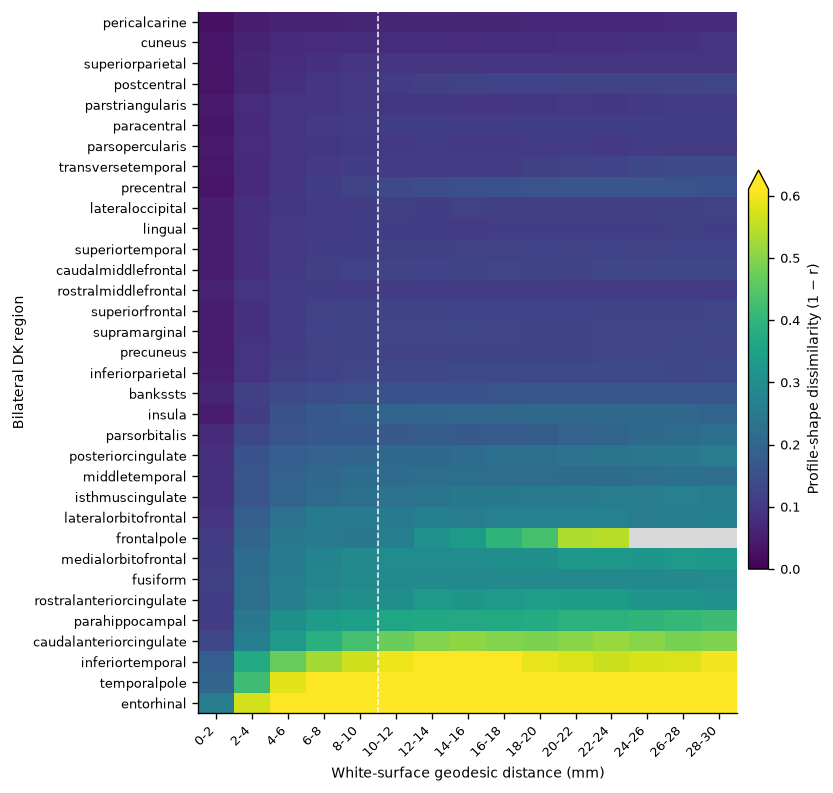

In [19]:
if not RESULTS_READY:
    print('Skipped curve-heatmap: regional summary is not ready.')
else:
    region_order = (
        group.loc[group['distance_bin_index'].lt(5) & group['coverage_pass']]
        .groupby('anchor_region')['dissimilarity_median'].mean()
        .sort_values().index.tolist()
    )
    bin_order = (
        group[['distance_bin_index', 'distance_bin']].drop_duplicates()
        .sort_values('distance_bin_index')['distance_bin'].tolist()
    )
    matrix = group.pivot(
        index='anchor_region', columns='distance_bin', values='dissimilarity_median'
    ).reindex(index=region_order, columns=bin_order)
    coverage_matrix = group.pivot(
        index='anchor_region', columns='distance_bin', values='coverage_pass'
    ).reindex(index=region_order, columns=bin_order)
    matrix = matrix.where(coverage_matrix)
    reliable_values = matrix.to_numpy(float)
    vmax = float(np.nanquantile(reliable_values, 0.95))

    cmap = plt.get_cmap('viridis').copy()
    cmap.set_bad(PALETTE['masked'])
    fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 6.8))
    image = ax.imshow(
        np.ma.masked_invalid(reliable_values), aspect='auto', interpolation='nearest',
        cmap=cmap, vmin=0, vmax=vmax,
    )
    ax.set_xticks(np.arange(len(bin_order)), labels=bin_order, rotation=45, ha='right')
    ax.set_yticks(np.arange(len(region_order)), labels=region_order)
    ax.set(xlabel='White-surface geodesic distance (mm)', ylabel='Bilateral DK region')
    ax.axvline(4.5, color='white', linestyle='--', linewidth=0.9)
    ax.spines[['top', 'right']].set_visible(False)
    colorbar = fig.colorbar(image, ax=ax, pad=0.02, fraction=0.035, extend='max')
    colorbar.set_label('Profile-shape dissimilarity (1 − r)')
    fig.subplots_adjust(left=0.25, right=0.92, bottom=0.12, top=0.98)
    save_publication_figure(fig, FIGURE_DIR / 'Figure4_region_real_dissimilarity_heatmap')
    plt.show()

## Sampling coverage QC

The left heatmap shows the median subject-level $K_{effective}$ after profile validity masking. The right heatmap shows the median fraction of fixed anchor-bins retaining all 15 pairs. These diagnostics must be inspected before interpreting small regions such as entorhinal, frontal pole, and temporal pole.

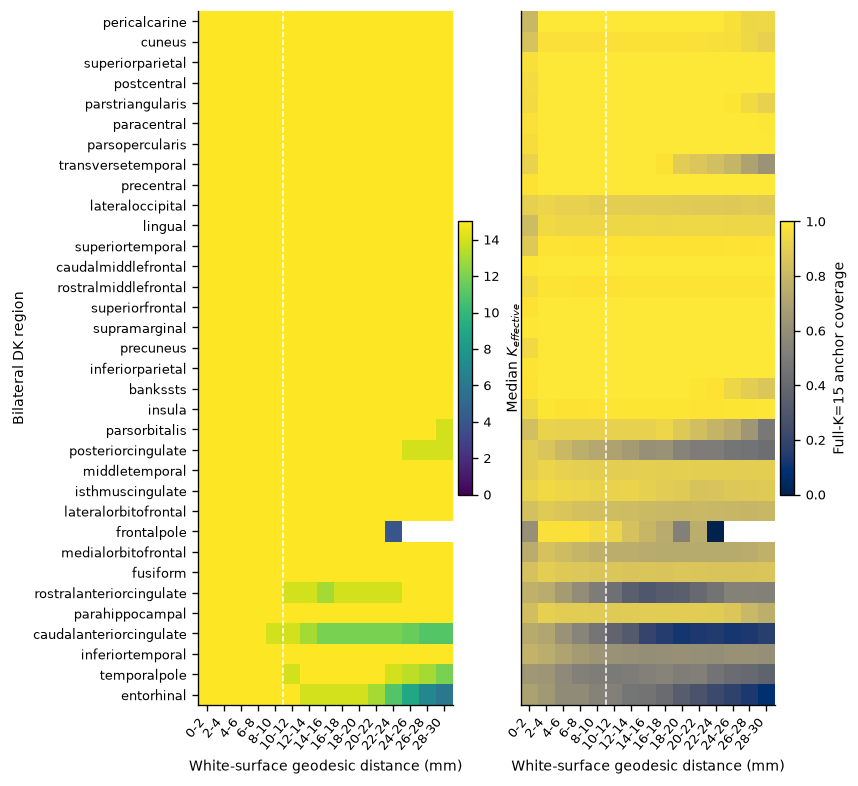

In [20]:
if not RESULTS_READY:
    print('Skipped coverage: regional summary is not ready.')
else:
    coverage_specs = [
        ('median_k_effective', r'Median $K_{effective}$', 'viridis', 0, 15),
        ('full_k15_coverage_median', 'Full-K=15 anchor coverage', 'cividis', 0, 1),
    ]
    fig, axes = plt.subplots(1, 2, figsize=(FIGURE_WIDTH_IN, 6.8), sharey=True)
    for index, (metric, label, cmap_name, vmin, vmax_metric) in enumerate(coverage_specs):
        ax = axes[index]
        values = group.pivot(
            index='anchor_region', columns='distance_bin', values=metric
        ).reindex(index=region_order, columns=bin_order)
        image = ax.imshow(
            np.ma.masked_invalid(values.to_numpy(float)), aspect='auto',
            interpolation='nearest', cmap=cmap_name, vmin=vmin, vmax=vmax_metric,
        )
        ax.set_xticks(np.arange(len(bin_order)), labels=bin_order, rotation=50, ha='right')
        ax.set_xlabel('White-surface geodesic distance (mm)')
        if index == 0:
            ax.set_yticks(np.arange(len(region_order)), labels=region_order)
            ax.set_ylabel('Bilateral DK region')
        else:
            ax.tick_params(left=False, labelleft=False)
        ax.axvline(4.5, color='white', linestyle='--', linewidth=0.9)
        ax.spines[['top', 'right']].set_visible(False)
        colorbar = fig.colorbar(image, ax=ax, pad=0.02, fraction=0.05)
        colorbar.set_label(label)
    fig.subplots_adjust(left=0.25, right=0.95, bottom=0.13, top=0.98, wspace=0.18)
    save_publication_figure(fig, FIGURE_DIR / 'Figure4_region_sampling_coverage')
    plt.show()

## Region-level correlation length

Each subject is fitted independently with $D(d)=D_\infty-A\exp(-d/\lambda)$. The plot shows the median and subject IQR among acceptable fits. Regions with fewer acceptable fits than the 80%-of-cohort threshold are shown in neutral gray and should be treated as QC-only.

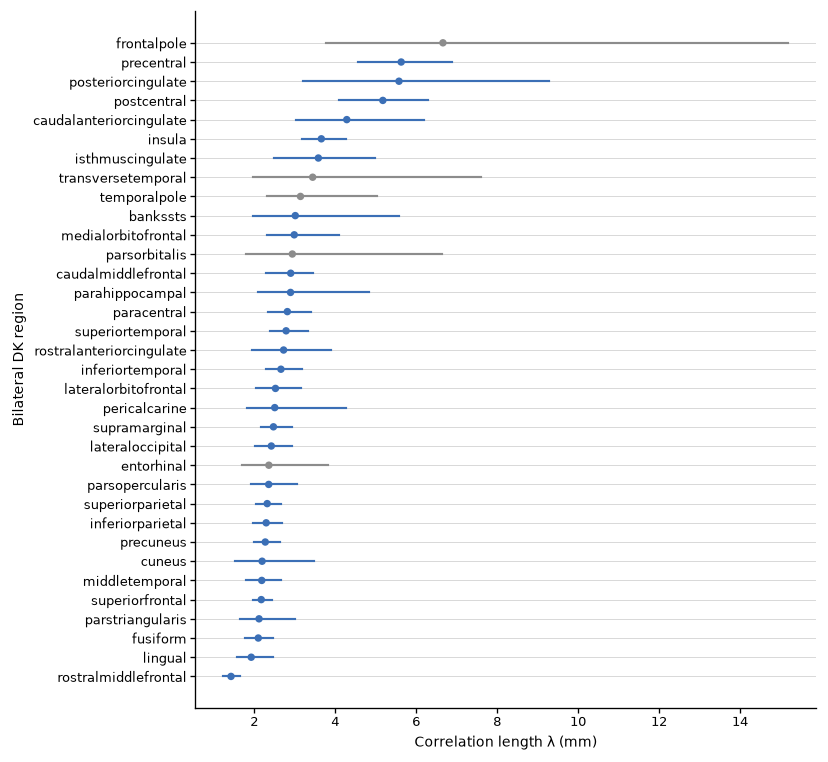

,anchor_dk_label,anchor_region,n_subjects_attempted,n_fit_success,n_boundary,n_acceptable,lambda_median_mm,lambda_q25_mm,lambda_q75_mm,d_infinity_median,amplitude_median,fit_r2_median,lambda_coverage_pass
0,27,rostralmiddlefrontal,325,324,0,324,1.425742,1.236424,1.643090,0.110241,0.149709,0.951605,True
1,13,lingual,325,324,0,324,1.924998,1.574574,2.471018,0.112170,0.134064,0.929205,True
2,7,fusiform,325,324,0,323,2.099384,1.771949,2.454899,0.290713,0.356554,0.946784,True
3,20,parstriangularis,325,324,14,310,2.118111,1.649958,2.999481,0.102170,0.111545,0.862856,True
4,28,superiorfrontal,325,324,0,324,2.172812,1.974754,2.437499,0.125836,0.150712,0.977844,True
5,15,middletemporal,325,324,0,324,2.184956,1.807756,2.658508,0.219137,0.248028,0.950246,True
6,5,cuneus,325,324,34,286,2.193581,1.520657,3.486218,0.083603,0.089717,0.821970,True
7,25,precuneus,325,325,0,324,2.271895,1.985805,2.632885,0.127504,0.145145,0.969071,True
8,8,inferiorparietal,325,324,0,324,2.294205,1.970102,2.694781,0.134101,0.149657,0.972737,True
9,29,superiorparietal,325,324,0,324,2.319688,2.033081,2.667392,0.094408,0.105210,0.975706,True


In [21]:
if not RESULTS_READY:
    print('Skipped lambda: regional summary is not ready.')
else:
    lambda_plot = group_lambda.sort_values('lambda_median_mm').reset_index(drop=True)
    y = np.arange(len(lambda_plot))
    colors = np.where(
        lambda_plot['lambda_coverage_pass'], PALETTE['blue'], PALETTE['gray']
    )
    fig, ax = plt.subplots(figsize=(FIGURE_WIDTH_IN, 6.6))
    for row_index, row in lambda_plot.iterrows():
        ax.plot(
            [row['lambda_q25_mm'], row['lambda_q75_mm']], [row_index, row_index],
            color=colors[row_index], linewidth=1.3,
        )
    ax.scatter(
        lambda_plot['lambda_median_mm'], y, c=colors, s=12, zorder=3,
    )
    ax.set_yticks(y, labels=lambda_plot['anchor_region'])
    ax.set(
        xlabel='Correlation length λ (mm)', ylabel='Bilateral DK region',
    )
    style_axes(ax, grid=True)
    fig.subplots_adjust(left=0.25, right=0.98, bottom=0.10, top=0.98)
    save_publication_figure(fig, FIGURE_DIR / 'Figure4_region_correlation_lengths')
    plt.show()
    display(lambda_plot)

## Prespecified representative regional curves

These panels are diagnostic examples rather than a data-driven claim of regional specificity. The list contains commonly interpretable regions plus small-region coverage checks.

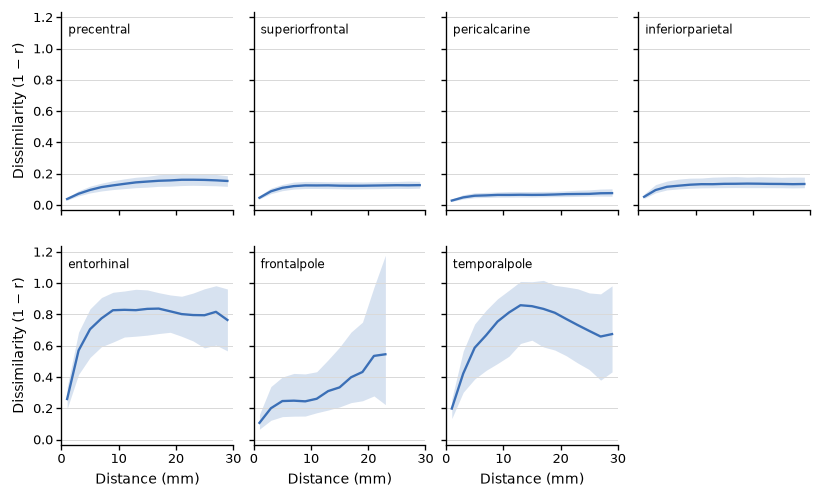

In [22]:
if not RESULTS_READY:
    print('Skipped representative: regional summary is not ready.')
else:
    requested_regions = [
        'precentral', 'superiorfrontal', 'pericalcarine', 'inferiorparietal',
        'entorhinal', 'frontalpole', 'temporalpole',
    ]
    representative_regions = [region for region in requested_regions if region in set(group['anchor_region'])]
    fig, axes = plt.subplots(2, 4, figsize=(FIGURE_WIDTH_IN, 4.2), sharex=True, sharey=True)
    for ax, region in zip(axes.flat, representative_regions):
        frame = group.loc[group['anchor_region'].eq(region)].sort_values('distance_bin_index')
        valid = frame['coverage_pass']
        x = frame.loc[valid, 'distance_bin_index'].to_numpy(float) * 2 + 1
        ax.plot(x, frame.loc[valid, 'dissimilarity_median'], color=PALETTE['blue'])
        ax.fill_between(
            x, frame.loc[valid, 'dissimilarity_q25'], frame.loc[valid, 'dissimilarity_q75'],
            color=PALETTE['blue'], alpha=0.2, linewidth=0,
        )
        ax.text(0.04, 0.94, region, transform=ax.transAxes, va='top', fontsize=7)
        ax.set(xlim=(0, 30), xticks=[0, 10, 20, 30])
        style_axes(ax, grid=True)
    for ax in axes.flat[len(representative_regions):]:
        ax.set_visible(False)
    for ax in axes[-1, :]:
        if ax.get_visible():
            ax.set_xlabel('Distance (mm)')
    for ax in axes[:, 0]:
        ax.set_ylabel('Dissimilarity (1 − r)')
    fig.subplots_adjust(left=0.11, right=0.99, bottom=0.12, top=0.98, hspace=0.18, wspace=0.12)
    save_publication_figure(fig, FIGURE_DIR / 'Figure4_region_representative_real_curves')
    plt.show()

## DK surface map of correlation length

This is a descriptive map of the bilateral region medians. Regions failing the fit-coverage criterion are masked. Both hemispheres use the same color limits and shared colorbar.

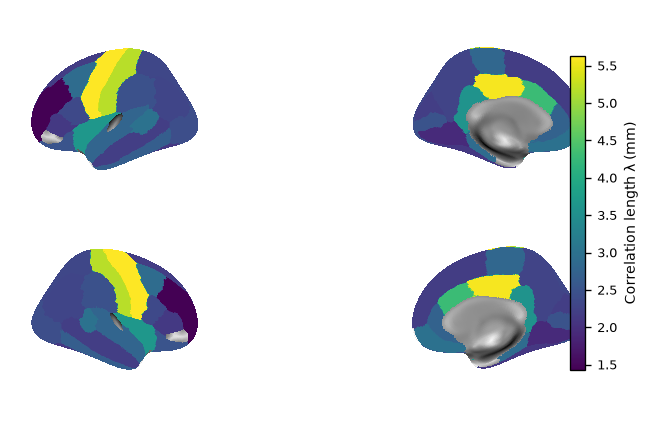

In [23]:
if not RESULTS_READY:
    print('Skipped surface: regional summary is not ready.')
else:
    reliable_lambda = group_lambda.loc[group_lambda['lambda_coverage_pass']].copy()
    value_by_region = reliable_lambda.set_index('anchor_region')['lambda_median_mm'].to_dict()
    surface_values = {}
    for hemisphere in ('lh', 'rh'):
        labels, _, names = fsio.read_annot(str(TEMPLATE_ROOT / 'label' / f'{hemisphere}.aparc.annot'))
        names = [name.decode() if isinstance(name, bytes) else str(name) for name in names]
        values = np.full(labels.shape, np.nan, dtype=float)
        for label_index, region_name in enumerate(names):
            if region_name in value_by_region:
                values[labels == label_index] = value_by_region[region_name]
        surface_values[hemisphere] = values

    all_values = np.concatenate([values[np.isfinite(values)] for values in surface_values.values()])
    vmin, vmax = np.quantile(all_values, [0.02, 0.98])
    fig = plt.figure(figsize=(FIGURE_WIDTH_IN, 3.4))
    grid = fig.add_gridspec(2, 2, wspace=0.0, hspace=0.0)
    for row, hemisphere in enumerate(('lh', 'rh')):
        for column, view in enumerate(('lateral', 'medial')):
            ax = fig.add_subplot(grid[row, column], projection='3d')
            plotting.plot_surf_stat_map(
                surface.load_surf_mesh(TEMPLATE_ROOT / 'surf' / f'{hemisphere}.inflated'),
                surface_values[hemisphere], hemi='left' if hemisphere == 'lh' else 'right',
                view=view, cmap='viridis', vmin=vmin, vmax=vmax, colorbar=False,
                bg_map=surface.load_surf_data(TEMPLATE_ROOT / 'surf' / f'{hemisphere}.sulc'),
                axes=ax,
            )
            ax.set_axis_off()
    normalizer = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    colorbar = fig.colorbar(
        mpl.cm.ScalarMappable(norm=normalizer, cmap='viridis'), ax=fig.axes,
        orientation='vertical', fraction=0.025, pad=0.015,
    )
    colorbar.set_label('Correlation length λ (mm)')
    fig.subplots_adjust(left=0.01, right=0.91, bottom=0.01, top=0.99)
    save_publication_figure(fig, FIGURE_DIR / 'Figure4_region_correlation_length_surface')
    plt.show()

## Interpretation boundary

- The real regional curves show heterogeneity in observed profile-shape dissimilarity and spatial scale.
- Coverage diagnostics determine whether an apparent regional difference is estimable with the fixed $K=15$ design.
- Until the identical region-level acquisition-and-sampling null is computed, these results do **not** establish regional differences in null-adjusted local organization.
- No multiple-comparison testing is performed in this descriptive/QC stage.